In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [ ]:
df_log = pd.read_csv("/content/drive/MyDrive/archive/diabetes.csv")

In [ ]:
df_log.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Outcome being a column of either or Or; It is either Yes or No, so this is logistic regression.
Logistics regression is a model used to predict yes or no answers. Instead pf predicting a number(like house price),
it predicts a probability and then turns it into a category (yes/no, 1/0, etc)

It answers:

Will a customer buy or not buy?

Is an email span or not spam?

Will a person get sick or stay healthy?

In [ ]:
df_log.info() #this shows there are no missing values. Note python doesn't count a zero entry as a missing value

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df_log.isnull().sum() #no null values

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df_log.describe() #Ex:how can min of glucose level be zero? no human has a 0 glucose level. It missing the person that
# entered the data treated missing data entries/values as zero. BUT python wouldn't treat zero as a missing value.

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Zero values are likely placeholders for missing data and should be handled

In [ ]:
(df_log == 0).sum() # all the rows that have zero values, sum the number of rows with 0 in each column

,0
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,500


Prgenancy: While 111 entries have a value of 0, this is valid, as some individuals may not have been pregannt

Outcome : A value of 0 indictates no diabeletes  and 500 entries show this. It shows a lot of individuals
in this dataset are non-diabetic

#Replacing zeros with NaN ( Not a Number)
In some datasets, 0 is used to represent missing or unrecorded values, a real mising value should
be represented as NaN in python

Glucose = 0 (no living human can have a glucose level of zero)

Blood Pressure = 0 NOT POSSIBLE

Replacing it with NaN marks it as missing so that it:
it doesn't affect analysis

NaN is recognized by pandas and scikit as "Missing"

So you look at the columns where it is not ok to have zero values: Glucose, BloodPressure,SkinThickness,"Insulin","BMI

No Human can have zero glucose level, no human can have zero insulin level, etc

In [ ]:
#List of columns where zero is physiologically invalid
invalid_zero_cols = ["Glucose", "BloodPressure","SkinThickness","Insulin","BMI"]

df_log[invalid_zero_cols] = df_log[invalid_zero_cols].replace(0,np.nan)

.replace(0, np.nan)

replaces all values equal to 0 in those columns with np.nan, which stands for 'Not a number' a standard
way to represent missing data in pandas.

Np.nan is a numpy fxn that changes a zero value to 'not a number' value.
np because this is a numpy fxn.

Pandas for manipulation, numpy for numerical computation.

In [ ]:
df_log.isnull().sum() #now we have null values after telling python the zeros are missing values because
#remember initially python doesn't treat 0 as missing values unless we tell it to

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
df_log.info() #compare this info to the first info we did when we started this notebook. This info has missing values
# and it shows that python now understands to treat the Zeros in these column as missing values as we have told it to.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   763 non-null    float64
 2   BloodPressure             733 non-null    float64
 3   SkinThickness             541 non-null    float64
 4   Insulin                   394 non-null    float64
 5   BMI                       757 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


In [ ]:
df_log.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,763.000000,733.000000,541.000000,394.000000,757.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.535641,12.382158,10.476982,118.775855,6.924988,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,22.000000,76.250000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,141.000000,80.000000,36.000000,190.000000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


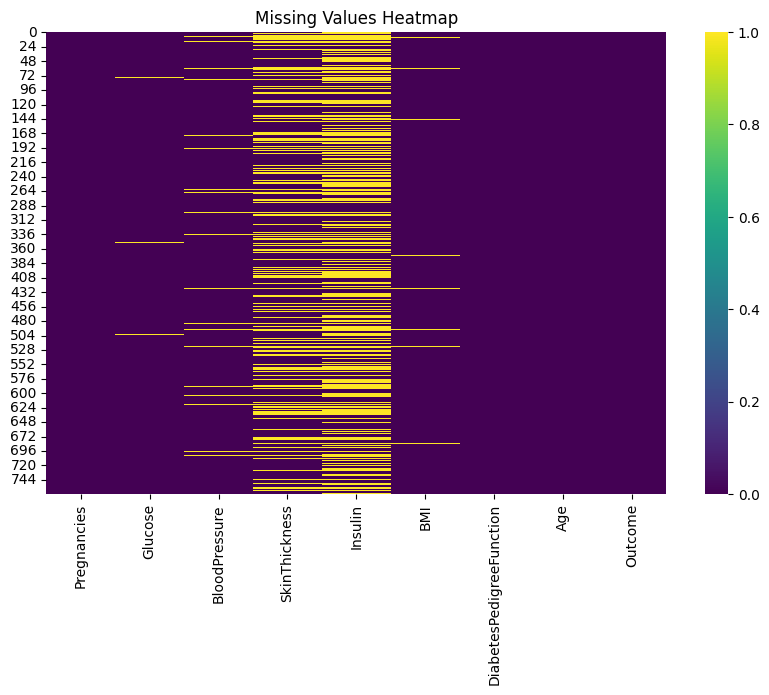

In [ ]:
plt.figure(figsize =(10,6))
sns.heatmap(df_log.isnull(), cmap = 'viridis', cbar = True) #heat map shows the intensity of a what is happening,
#Here we want to visulaize the null values (missing values). cbar = True shows the bar of the intensity and we are
#only looking at 1 or 0, 1 being yellow that they are missing values and 0 being the color palette, veridis
# means no missing values; cmap : color palette of the map;  viridis is a color palette.
plt.title("Missing Values Heatmap")
plt.show()


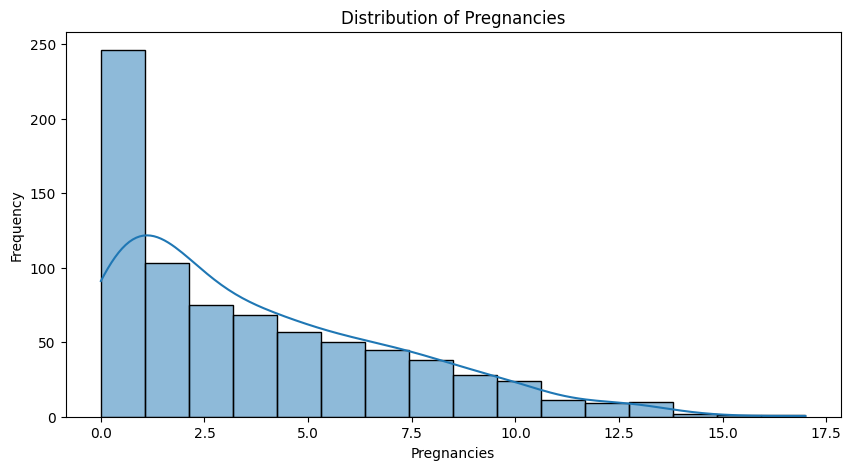

In [ ]:
plt.figure(figsize = (10,5))
sns.histplot(data = df_log, x = 'Pregnancies', kde= True) # histogram in seaborn, we calling forth the dataset first
#as data = df_log, then the x value we want to visualize. kde is curve on the histogram
plt.title('Distribution of Pregnancies')
plt.xlabel('Pregnancies')
plt.ylabel('Frequency')
plt.show()

The distribution is skewed to the right with a peak at 0-1 pregnancies.


This suggests that a large number of individuals in the dataset have had few or no pregancies. Like 1 0r 2 persons have had 17 pregnancies(17 children), like 5 ppl have had 12 pregrancies each(12 children); 20 ppl have had 10 pregnancies each (10 children); most ppl have had no pregnancy(no child) or one pregnancy (1 child)

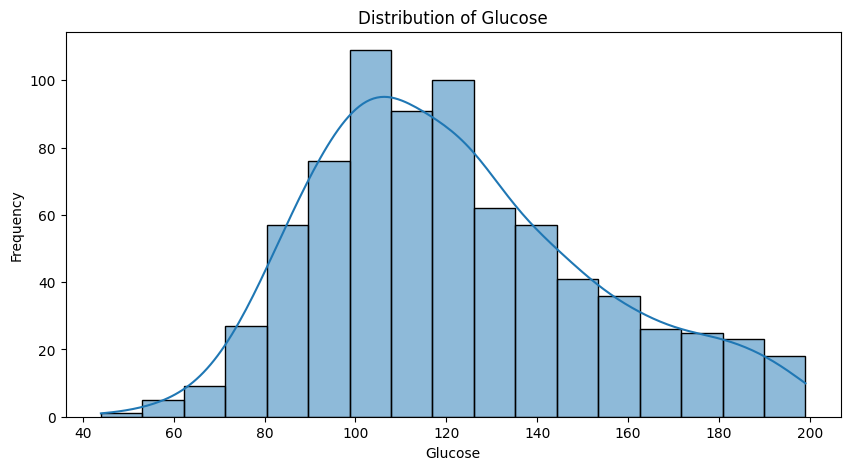

In [ ]:
plt.figure(figsize =(10,5))
sns.histplot(data = df_log, x ='Glucose', kde = True)
plt.title('Distribution of Glucose')
plt.xlabel('Glucose')
plt.ylabel('Frequency')
plt.show()

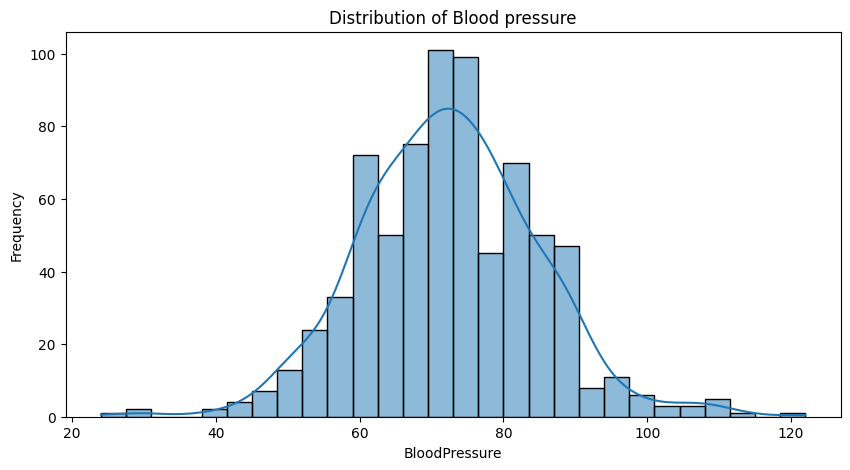

In [ ]:
plt.figure(figsize =(10,5))
sns.histplot(data = df_log, x ='BloodPressure', kde = True)
plt.title('Distribution of Blood pressure')
plt.xlabel('BloodPressure')
plt.ylabel('Frequency')
plt.show()

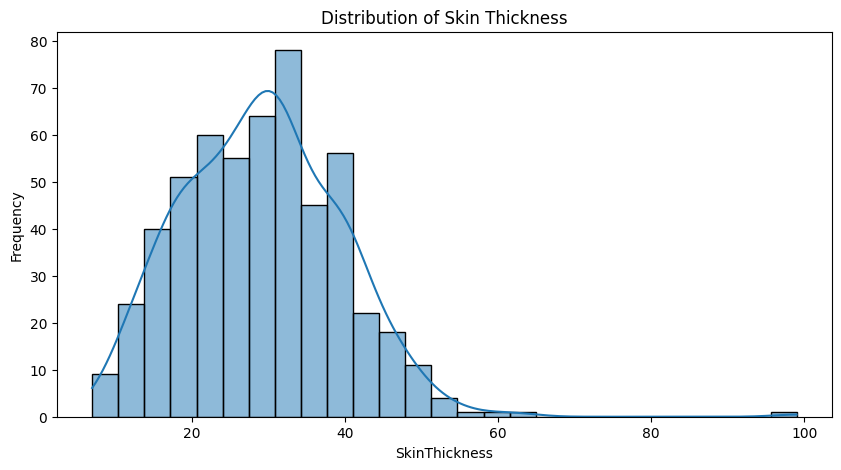

In [ ]:
plt.figure(figsize =(10,5))
sns.histplot(data = df_log, x ='SkinThickness', kde = True)
plt.title('Distribution of Skin Thickness')
plt.xlabel('SkinThickness')
plt.ylabel('Frequency')
plt.show()

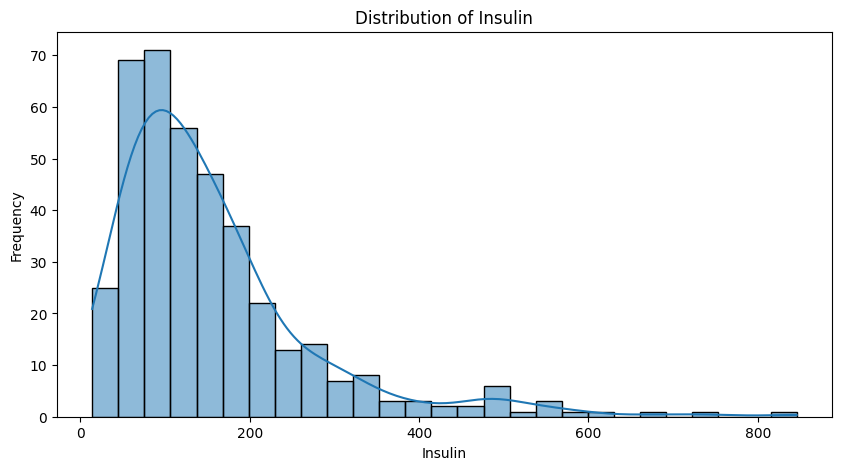

In [ ]:
plt.figure(figsize =(10,5))
sns.histplot(data = df_log, x ='Insulin', kde = True)
plt.title('Distribution of Insulin')
plt.xlabel('Insulin')
plt.ylabel('Frequency')
plt.show()

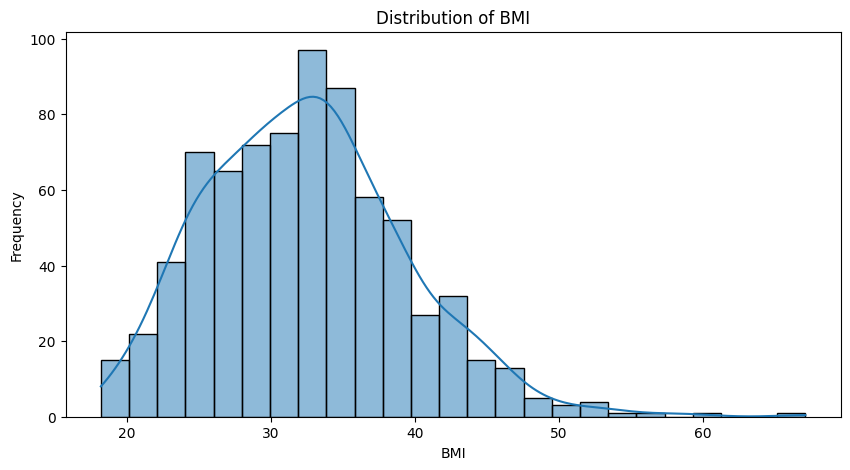

In [ ]:
plt.figure(figsize =(10,5))
sns.histplot(data = df_log, x ='BMI', kde = True)
plt.title('Distribution of BMI')
plt.xlabel('BMI')
plt.ylabel('Frequency')
plt.show()

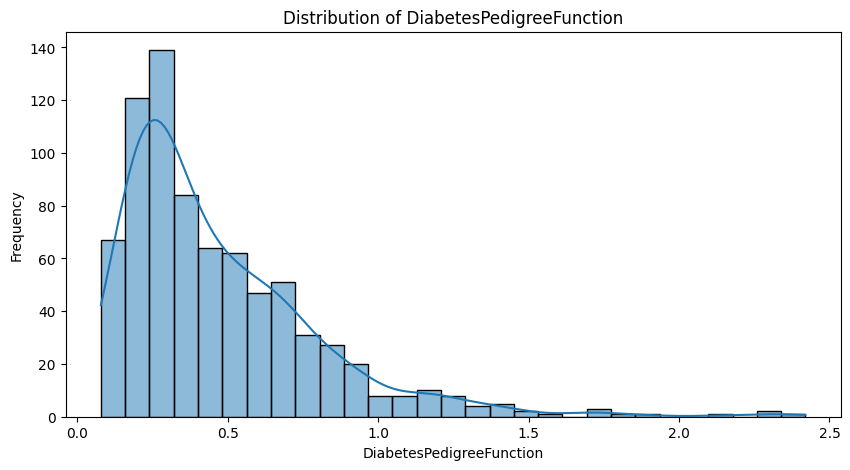

In [ ]:
plt.figure(figsize =(10,5))
sns.histplot(data = df_log, x ='DiabetesPedigreeFunction', kde = True)
plt.title('Distribution of DiabetesPedigreeFunction')
plt.xlabel('DiabetesPedigreeFunction')
plt.ylabel('Frequency')
plt.show()

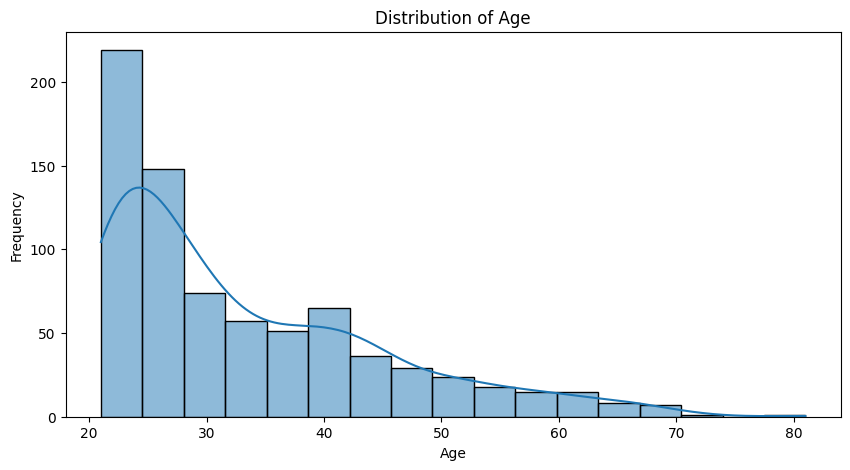

In [ ]:
plt.figure(figsize =(10,5))
sns.histplot(data = df_log, x ='Age', kde = True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

#Missing Values

There are different types of missing values.

1.) MCAR (Missing Completely at Random. Ex: in a sales daatset, someone forgot to fill in some answers on a survey and it is not related to
anything specific (like age, gender). Ex: there is a math column score, english column score and total score, if one row's math score is missing
you can minus english score from the total score

2.) MAR (Missing at Random): The missing data is related to other information you do have in your dataset but not to the missing value itself. Using a
known column to input missing information


3.) MNAR (Missing Not at Random): the reason data is missing is directly tied to the value that is missing. Ex: Someone has diabetes and on a survery bc they are
emabrrased they left that column blank when asked if they have diabetes.


#Common inputation
 Mean Imputation: Replace with mean. Use mean when predicting a continuos numerical value. Ex: if it is a regression, the mean is the best imputation


 Median Imputation : replace with median. When the graphs is uniformed/ when majority have uniformed level of ex: glucose level, then replace with median. Ex: if it is a classification, the median is the best imputation
 Classification model is a dataset of grouping things. Like this dataset we want to group ppl that have diabetes and ppl not living with diabetes based on info provide


 Mode Imputation : replace with Most frequent value. Ex: use mode when you're dealing with a missing value in an object (string) columns


 Constant Value Imputation: Replace with a fixed value like 0, -1, Unknown

In [ ]:
outcome_counts = df_log['Outcome'].value_counts()
print(outcome_counts)

Outcome
0    500
1    268
Name: count, dtype: int64


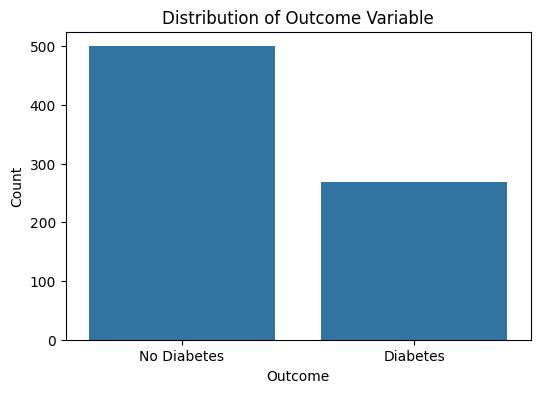

In [ ]:
plt.figure(figsize = (6,4))
sns.countplot(data = df_log, x ="Outcome")
plt.title('Distribution of Outcome Variable')
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.xticks(ticks = [0,1], labels = ['No Diabetes', 'Diabetes'])
plt.show()

In [ ]:
#Columns with missing values
cols_to_impute = ["Glucose", "BloodPressure","SkinThickness","Insulin","BMI"]

#Impute with the median of each column
df_log[cols_to_impute] = df_log[cols_to_impute].fillna(df_log[cols_to_impute].median())

#.fillna is a fxn to fill the N/A (missing b=values )
# fill missing values for the columns that didn't make sense to have 0, for ex if pregancy had zero is means the person is not prgenant but glucose cannot have zer bc no human glucose level is zero

In [ ]:
df_log.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [ ]:
X = df_log[["Pregnancies", "Glucose", "BloodPressure","SkinThickness","Insulin","BMI", "DiabetesPedigreeFunction", "Age"]]
y = df_log['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42, stratify = y)

#stratify = y makes the data balanced. In our dataset, ppl with diabetes are less than ppl without diabetes which is not a good dataset for this model, we need more ppl with diabetes if we intend on using this model to
# predict correctly for this case and future diabetes cases/programs.
# It makes the 20% test size the same proportion for ppl with and without diabetes Ex: 100 ppl filled out the survey, test size = 0.2 so 20 ppl for the test size. Since there is a random selection,
# it is possible that all 20 ppl chosen at random do not have diabetes but we dont want that, we want an equal distributuon for this test size so 'stratify = y' gives us 10 ppl with diabetes and 10 ppl without diabetes.

In [ ]:
model_log = LogisticRegression(max_iter = 1000)
model_log.fit(X_train, y_train)

#Remember we only use train dataset in the LogisticRegression formula for the model; to train the model
#max_iter = 1000, this learning will be repeated until you find a better prediction then you can stop.
#It tells the tool how many times it should try to learn from the data to get the best predictions. Ex: it is like telling a student to practice a math problem up to 1000 times to get it right. This keeps predicting until it is
#able to predict rightly

LogisticRegression(max_iter=1000)

In [ ]:
y_train_pred = model_log.predict(X_train)
print(y_train_pred[:10])

[0 0 0 0 0 1 0 1 0 0]


In [ ]:
results_df =pd.DataFrame({'Actual': y_train, 'Predicted': y_train_pred})
print("Actual vs Predicted Values")
display(results_df.head())


Actual vs Predicted Values


,Actual,Predicted
353,0,0
711,0,0
373,0,0
46,0,0
682,0,0


In [ ]:
feature_importance = pd.DataFrame({'Feature': X.columns, 'Coefficient': model_log.coef_[0]})
feature_importance = feature_importance.sort_values('Coefficient', ascending = False)
display(feature_importance)

,Feature,Coefficient
6,DiabetesPedigreeFunction,0.644358
0,Pregnancies,0.115651
5,BMI,0.103736
1,Glucose,0.040221
7,Age,0.012492
3,SkinThickness,0.002545
4,Insulin,-0.000939
2,BloodPressure,-0.004207


In [ ]:
y_test_pred = model_log.predict(X_test)
print(y_test_pred [:10])

[1 0 0 0 0 0 0 1 0 1]


In [ ]:
results_df_test =pd.DataFrame({'Actual': y_test, 'Predicted': y_test_pred})
print("Actual vs Predicted Values")
display(results_df_test.head())

Actual vs Predicted Values


,Actual,Predicted
44,0,1
672,0,0
700,0,0
630,1,0
81,0,0


#Accuracy score:
 is (number of correct predictions) / (total number of prediction). It measures how often our model's predictions are correct. It tells you how many times the model got it right
out of the total number of predictions

When you have an imbalance (the group we want to focus on is less than the other group, Ex: In this dataset, the ppl without diabetes are more than the ppl with diabetes) dataset, do not do accuracy score. The accuracy score will focus on the majority group, which is not helpful for us if we intend on use the model for future diabetes cases.



If we did this, since accuracy score = # of correct predictions/ total number of predictions, and there are more ppl without diabetes, the accuracy score will be mostly a representative of the majority class.

#WHY DO WE ALWAYS USE TEST SCORE

Test set is used for every analysis (regression, classification report, accuracy, etc). This is because the model hasnt seen the test set. Remember the training set is what trains the model and it is inside the model.
The model hasn't seen the test set. So we are saying "python from what you have learnt from the training set, apply that to the test set."



Traing set is like the teacher, it teaches the model. The TEST SET is what we always work with analyze with!

In [ ]:
#Accuracy on the training set
y_train_pred = model_log.predict(X_train)
train_accuracy = accuracy_score(y_train, y_train_pred)
print(f"Training Accuracy: {train_accuracy: .4f}")

Training Accuracy:  0.7932


In [ ]:
#Accuracy on the testing set

test_accuracy = accuracy_score(y_test, y_test_pred)
print(f"Testing Accuracy: {test_accuracy: .4f}")

Testing Accuracy:  0.7013


#Classification Report
TP: True positives


FP: false positives

#Precision:
of all the times the model predicted positive, how many were actually correct. TP/ (TP+FP)

#Recall:
Out of all actual 'positive' cases, how many did the model correctly predict ? TP/(TP + FN)

#F1 Score:
The harmonic mean of precision and recall. It gives a single score that balances both. F1 score = 2 x (precision x recall)/ (Precision + Recall)

High F1 means both precision and recall are high
Low F1 means at one of them is weak

F1 is useful when you want a balance and the classes are imbalanced


#Support:
The number of actual occurences of each class in your dataset

In [ ]:
#Classification report
print(f"\nClassification Report (Test Set):")
print(classification_report(y_test, y_test_pred))

# the class 0 in the results is the majority (ppl without diabetes) while the class 1 is the minority class (ppl with diabetes). Because 1 has less data, it performed poorly based on the results compared to 0 row (the majority)


Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



In [ ]:
#Confusion Matrix
print(f"\nConfusion Matrix (Test Set):")
cm = confusion_matrix(y_test, y_test_pred)
print(cm)


Confusion Matrix (Test Set):
[[81 19]
 [27 27]]


Top left (true positive) of the confusion matrix: majority correct predictions, top right (false positive) of the confusion matrix: number of ppl that we are not sure of (that are wthout diabetes).
Bottom right (true Negative) of the confusion matrix: number of ppl from minority that have correct predictions; Ex: number of living with diabetes and
bottom left (False negative) of the confusion matrix: number of ppl from the group of ppl with diabetes that we are not sure of and this could be the information we had about ppl with diabetes was limited so that is
why they would be a lot of ppl in the bottom left that we are not sure of if they have diabetes.

#The model will ignore the outcome in the dataset and it will give its own prediction

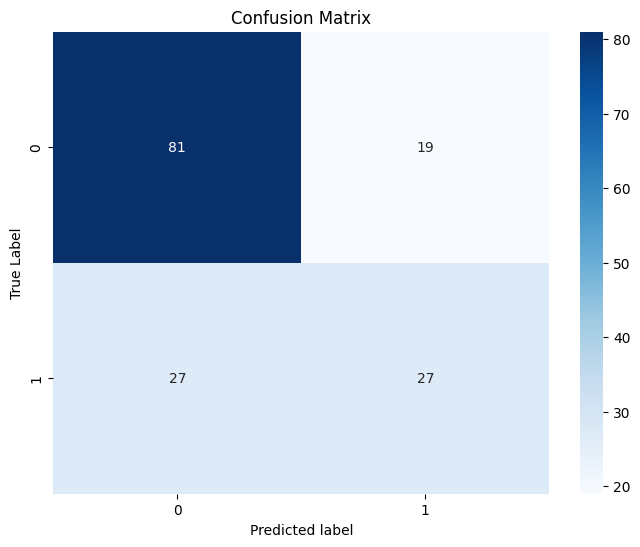

In [ ]:
plt.figure(figsize =(8,6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues') #'cm' is confusion matrix, telling it to plot a confusion matrix, fmt: 'd', telling it to include numbers(integers) in the middle of each CM box.
plt.title('Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('True Label')
plt.show()
